> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage5_lineage_and_evaluation_ko.ipynb`)](../ko/stage5_lineage_and_evaluation_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/05_stage5_lineage_and_eval_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage5)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → **[▶ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)**

---

# Stage 5. [Verify & Gate] End-to-End Data Lineage, Golden CQ Audit & 50-Trial Boundary Benchmark
## Step 5.1 Source File → Chunk → Rule → Contract → CQ Lineage · Step 5.2 5 Golden CQs & 10×5 Boundary Benchmark Release Gate

Stage 5 completes **Phase 8 (Verification & Release Gate)**. Using `stage5_resource_check`, `src/lineage/lineage_engine.py`, and `H.recheck_cq()`, we verify **(1) the End-to-End Data Lineage (`Source File → DocChunk → DomainRule (W1~W3) → CustomerContract → Golden CQ`)**, **(2) deterministic SQL ground-truth auditing across all 5 Golden CQs**, **(3) 10 Boundary Cases × 5 repeated trials (50 live runs) for success, consistency, and intent stability**, and **(4) the Gate 1–5 Production Release Readiness Checklist**.

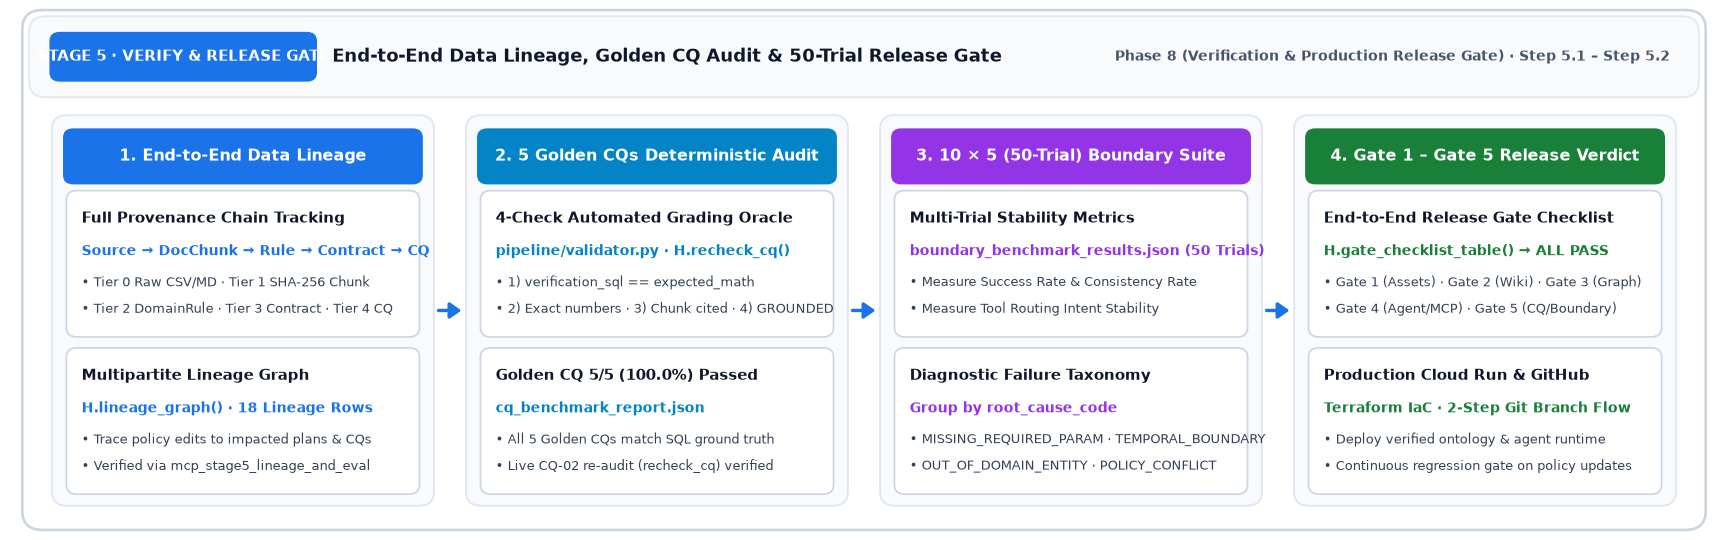


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 8a: End-to-End Data Lineage Verification] `stage5_resource_check`, Lineage Join (`%%bqsql`) & Multipartite Lineage Graph


In [ ]:
res_s5 = server.execute_tool("stage5_resource_check", {"steps": ["build_4tier_lineage", "run_golden_cq_suite", "diagnose_boundary_failures"]})
H.show_tool(res_s5)


In [ ]:
%%bqsql df_lineage
SELECT c.contract_id, c.customer_id, d.device_name, p.plan_name, s.policy_id,
       e.rule_id, e.source_chunk_id, ch.content_sha256 AS anchor, ch.source_file
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d ON d.device_id = c.device_id
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p ON p.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s ON s.device_id = c.device_id AND s.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e ON e.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = e.source_chunk_id
ORDER BY c.contract_id, e.rule_id


In [ ]:
H.show(df_lineage)
cq_rep = H.read_json("data/output/cq_benchmark_report.json")
lnodes, ledges = H.lineage_graph(H.pdf(df_lineage).to_dict("records"), cq_rep["test_results"])
H.draw_graph(lnodes, ledges,
             "End-to-End Data Lineage Multipartite Graph (Source File → DocChunk → DomainRule → Contract → CQ)",
             layout="layers", figsize=(12, 6.0),
             legend={"Tier 0 Source File": "#5F6368", "Tier 1 DocChunk": "#9334E6", "Tier 2 DomainRule": "#F9AB00",
                     "Tier 3 Contract": "#1A73E8", "Tier 4 Golden CQ": "#188038"})


#### Studio lineage DAG (`config/lineage_spec.json`), measured
Same engine as the studio `Stage 5` lineage (`src/lineage/lineage_engine.py`). Volumes are BigQuery `__TABLES__` row counts, GCS object counts and node/edge table counts from `INFORMATION_SCHEMA.PROPERTY_GRAPHS`, queried now; a failed lookup stays `lookup failed`.

**Structure principle (method)**: one box per structured table and one box per edge-table kind. Unstructured documents flow RAW → parsed → re-extraction gate → latest → one box per ontology document; the Wiki Agent input is the ontology latest on GCS. The remote MCP server is not drawn as a box.

**Starter spec**: structured tables (`RAW_TB_*`) and edge tables (`TR_EDGE_*`) have one box each, and the graph layer has a separate node-label box per table (`SEM_NODE_*`). Unstructured documents flow from 2 guide boxes → chunker (`tb_doc_chunks`) → GCS `parsed/` and one wiki box (`gs://{bucket}/ontology/`). There is no re-extraction gate, no `latest` promotion, no per-document ontology box, no Wiki Agent box and no remote MCP server box.


In [ ]:
from src.lineage.lineage_engine import LineageEngine
lg = LineageEngine(str(H.ROOT / "config" / "lineage_spec.json"), {
    "project_id": server.project_id, "fq": server.fq, "dataset_id": server.fq.split(".", 1)[1],
    "bucket": server.gcs_bucket, "model": agent.model_name,
    "spanner_instance": server.spanner_instance_id, "spanner_database": server.spanner_database_id}).build_graph()
H.md(f"**nodes `{lg['stats']['total_nodes']}` · edges `{lg['stats']['total_edges']}` · categories `{lg['stats']['total_categories']}` · "
     f"measured `{lg['metadata']['live_nodes']}/{lg['metadata']['bq_nodes']}` · errors `{lg['metadata']['bq_error'] or 0}`**")
H.show(pd.DataFrame([{"category": n["cat"], "node": n["id"], "volume": n["volume_en"], "measured": n["live"], "source": n["live_src"]}
                     for n in lg["nodes"] if n["live_src"]]))


### 2. [Phase 8b: 5 Golden CQs Deterministic Audit (`H.recheck_cq`)] Benchmark Report & Live Agent Re-Verification


#### Evaluation order: A overall results → B per-CQ verification → C rubric criteria
A is the pass count, rubric average, number of CQs with deductions and per-axis averages. B is, per CQ, the expected value and verification SQL result, score, verdict and deduction count, and evidence (cited chunk, verification job ID, agent BigQuery job count, judge summary). C is the rubric axis definitions. All values are read from `data/output/cq_benchmark_report.json`. The starter report stores rubric descriptions in English only (no `name_ko`, `desc_ko`, `judge_instructions_ko` fields). The answer text is stored in Korean, so the Korean notebook adds an answer excerpt per CQ and this English notebook shows the judge summary only. Finally, `CQ-02` is re-run now to check the grading conditions.


In [ ]:
df_cq = pd.DataFrame(cq_rep["test_results"])
H.md("#### A. Overall results")
H.md(f"**Golden CQ Benchmark `{cq_rep['benchmark_id']}`** · Evaluated `{cq_rep['evaluated_at']}` · Model `{cq_rep['model']}` · Passed **`{cq_rep['passed']}/{cq_rep['total_cqs']} ({cq_rep['accuracy_rate']}%)`** · "
     f"Rubric avg `{cq_rep['rubric_avg_total']}` · CQs with deductions `{sum(1 for r in cq_rep['test_results'] if r['rubric']['deductions'])}` · LLM tokens `{cq_rep['llm_tokens_total']:,}`")
H.show(pd.DataFrame([cq_rep["rubric_axis_avg"]]))

H.md("#### B. Per-CQ verification (score and evidence)")
df_cq["score"] = df_cq["rubric"].map(lambda r: r["scores"]["total"])
df_cq["verdict"] = df_cq["rubric"].map(lambda r: r["verdict"])
df_cq["deductions"] = df_cq["rubric"].map(lambda r: len(r["deductions"]))
df_cq["judge_summary"] = df_cq["rubric"].map(lambda r: r["summary"])
df_cq["agent_bq_jobs"] = df_cq["agent_bq_job_ids"].map(len)
H.show(df_cq, ["cq_id", "status", "expected_math", "verification_sql_result", "verification_job_id", "score", "verdict", "deductions",
               "grounded_chunk", "agent_bq_jobs", "llm_tokens", "elapsed_s", "judge_summary"])
H.bar(df_cq, "cq_id", "elapsed_s", "Golden CQ Agent 2-Pass Elapsed Time (s)", fmt="{:.2f}")

H.md("#### C. Rubric criteria")
H.show(pd.DataFrame(cq_rep["rubric"]))

cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
res_cq2, df_chk = H.recheck_cq(cqs[1], agent)
H.show_agent(res_cq2, title="Live Re-Audit: CQ-02")
H.show(df_chk)


### 3. [Phase 8c: 10 Boundary Cases × 5 Trials (50 Runs) Stability Evaluation & Gate 1–5 Release Verdict]


In [ ]:
b_rep = H.read_json("data/output/boundary_benchmark_results.json")
df_bc = pd.DataFrame(b_rep["cases"])
H.md(f"**Boundary Benchmark `{b_rep['benchmark_id']}`** · Trials=`{b_rep['total_trials']}` · "
     f"avg_success_rate=`{b_rep['avg_success_rate']}%` · avg_consistency_rate=`{b_rep['avg_consistency_rate']}%` · "
     f"avg_intent_stability=`{b_rep['avg_intent_stability']}%`")
H.show(df_bc, ["case_id", "root_cause_code", "missing_context", "trials", "passed_trials", "success_rate", "consistency_rate", "intent_stability"])
H.grouped_bar(df_bc, "case_id", ["success_rate", "consistency_rate", "intent_stability"],
              "Boundary 10 Cases × 5 Trials Metrics (%)")
df_tax = df_bc.groupby("root_cause_code", as_index=False).agg(
    cases=("case_id", "count"), avg_success=("success_rate", "mean"),
    avg_consistency=("consistency_rate", "mean"), avg_intent_stability=("intent_stability", "mean"))
H.show(df_tax)
H.md("#### Gate 1 – Gate 5 Production Release Readiness Verdict")
H.show(H.gate_checklist_table())


### Q&A
- **Q.** How does the Golden CQ audit (`H.recheck_cq`) grade agent accuracy and verify zero hallucination?
  - **A.** For every Golden CQ it checks (1) independent BigQuery `verification_sql` matches `expected_math`, (2) the answer contains the expected values (`_has` regex), (3) the required `DOC_CHUNK` is cited, (4) `answer_status == GROUNDED`, and (5) scores the final answer with an LLM rubric.

### Data Analysis Key Findings
- The end-to-end lineage join (`df_lineage`, 18 rows) traces every Golden CQ answer back through customer contracts, codified domain rules, and SHA-256 `DOC_CHUNK` anchors to the raw CSV and Markdown source files.
- Golden CQ report (2026-09-30): 5/5 passed (`100.0%`), rubric average `100.0`. See the table above for the live `CQ-02` re-check. Starter CQs ask for single values, so full scores are easy to reach.
- Boundary report (2026-09-27, 50 trials): average success `96.0%`, consistency `92.0%`, intent stability `78.0%`. The Gate 1–5 verdict follows the table above.

### Insights or Next Steps
- You have completed the full 5-Stage Agentic Ontology walkthrough! Use the navigation links below to revisit `0. Overview Home` or any Stage notebook (KO/EN), or replace `data/input/` with your own domain tables and policy guides.

---
> **Next Navigation**: [⬅️ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [🌐 Korean Version](../ko/stage5_lineage_and_evaluation_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/05_stage5_lineage_and_eval_en.md)
